# HRP-UWB: Step-by-Step Capture Analysis

This notebook processes the real generated **802.15.4z BPRF, channel 9, code 9, SP0** recording under `captures/generated/uwb`. Run the cells in order. Change `capture` to use a different generated HRP recording with a matching `.para2` file.

1. Read I/Q samples, sample rate, and PHY settings from the capture files.
2. Inspect the time-domain waveform and locate the burst.
3. Inspect the complex-baseband spectrum.
4. Examine preamble synchronization and repeated-symbol correlation.
5. Apply the measured frequency correction and inspect aligned preamble pulses.
6. Summarize the native receiver results and decoding limits.

**Scope:** the available native HRP receiver returns burst detection, preamble timing, repetition correlation, and frequency offset. It does not expose code-index selection, SFD/PHR parsing, BPM-BPSK payload decisions, FEC decoding, CRC, EVM, or a decoded PSDU. The preamble diagnostic below measures repetition, not a code-9 matched filter. The metadata's `PayloadHex` is generator ground truth, not received data. No payload constellation or decoded bits are invented.

In [1]:
%matplotlib inline
import csv
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

if os.name == "nt":
    packages = Path(os.environ["LOCALAPPDATA"]) / "Microsoft" / "WinGet" / "Packages"
    for runtime_dir in packages.glob("BrechtSanders.WinLibs.POSIX.UCRT_*/mingw64/bin"):
        os.environ["PATH"] = str(runtime_dir) + os.pathsep + os.environ.get("PATH", "")

root = next((directory for directory in (Path.cwd(), *Path.cwd().parents)
             if (directory / "nrdemod" / "python" / "nrdemod").is_dir()), None)
if root is None:
    raise FileNotFoundError("Run this notebook from within the nrdemod-vsa workspace")
sys.path.insert(0, str(root / "nrdemod" / "python"))
from nrdemod import demod
plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True})
print(f"Native demodulator {demod.version()}")
print(f"Workspace: {root}")

Native demodulator 1.0.0
Workspace: C:\code\nrdemod-vsa


In [2]:
# 1. Load a real HRP waveform and its generator settings.
capture = root / "captures/generated/uwb/UWB_4z_BPRF_ch9_CI9_SP0_PSDU127.txt"
metadata_path = capture.with_suffix(".para2")
if not (capture.is_file() and metadata_path.is_file()):
    raise FileNotFoundError(
        f"{capture.name} (+ .para2) not found in {capture.parent}. captures/ is not tracked by git; "
        "generate it with MATLAB: cd tools/uwb; gen_uwb")
settings = {}
with metadata_path.open(newline="", encoding="utf-8-sig") as stream:
    for row in csv.reader(stream, skipinitialspace=True):
        if len(row) >= 4:
            settings[row[1].strip()] = row[3].strip()

header = {}
with capture.open(encoding="utf-8-sig") as stream:
    for line in stream:
        if line.strip() == "Y":
            break
        parts = line.split()
        if len(parts) >= 2:
            header[parts[0]] = parts[1]
    else:
        raise ValueError("The capture has no Y data marker")
    samples = np.loadtxt(stream)
assert samples.ndim == 2 and samples.shape[1] == 2, "Expected I and Q columns"
iq = (samples[:, 0] + 1j * samples[:, 1]).astype(np.complex64)
fs = 1.0 / float(header["XDelta"])
assert np.isclose(fs, float(settings["SampleRate"]), rtol=1e-8)
assert iq.size == int(settings["NumSamples"])
assert np.isfinite(iq).all() and np.max(np.abs(iq)) > 0
mode = settings["Mode"].upper()
if mode not in {"BPRF", "HPRF"}:
    raise ValueError(f"Unsupported mode for this notebook: {mode}")
# The generator's PhyMode numbering is not the native API's numbering.
config = demod.Config(sampleRate=fs, phyMode={"BPRF": 0, "HPRF": 1}[mode],
                      syncLength=int(settings["SyncLength"]))
print(capture.name)
print(f"{iq.size:,} samples | {fs / 1e9:.5f} GSa/s | {iq.size / fs * 1e6:.3f} us")
print(f"{mode} | code {settings['CodeIndex']} | sync {config.syncLength} | SP{settings['StsPacketConfig']}")
print(f"Center frequency: {float(header['InputCenter']) / 1e9:.5f} GHz")
result = demod.demodulate(demod.UWB_HRP, iq, config)
assert result.ok, result.error
assert result.burstFound and result.syncFound, result.as_dict()
metrics = result.as_dict()
for name, value in metrics.items():
    print(f"{name:30s} {value}")

UWB_4z_BPRF_ch9_CI9_SP0_PSDU127.txt
506,548 samples | 1.99680 GSa/s | 253.680 us
BPRF | code 9 | sync 64 | SP0
Center frequency: 7.98720 GHz


burstFound                     True
syncFound                      True
burstStart                     4156
burstLength                    500722
syncPositionSamples            4156
syncRho                        0.9903901337375707
frequencyErrorHz               -0.0
preambleSymbolPeriodSamples    2032.0
ok                             True
error                          
family                         UWB-HRP


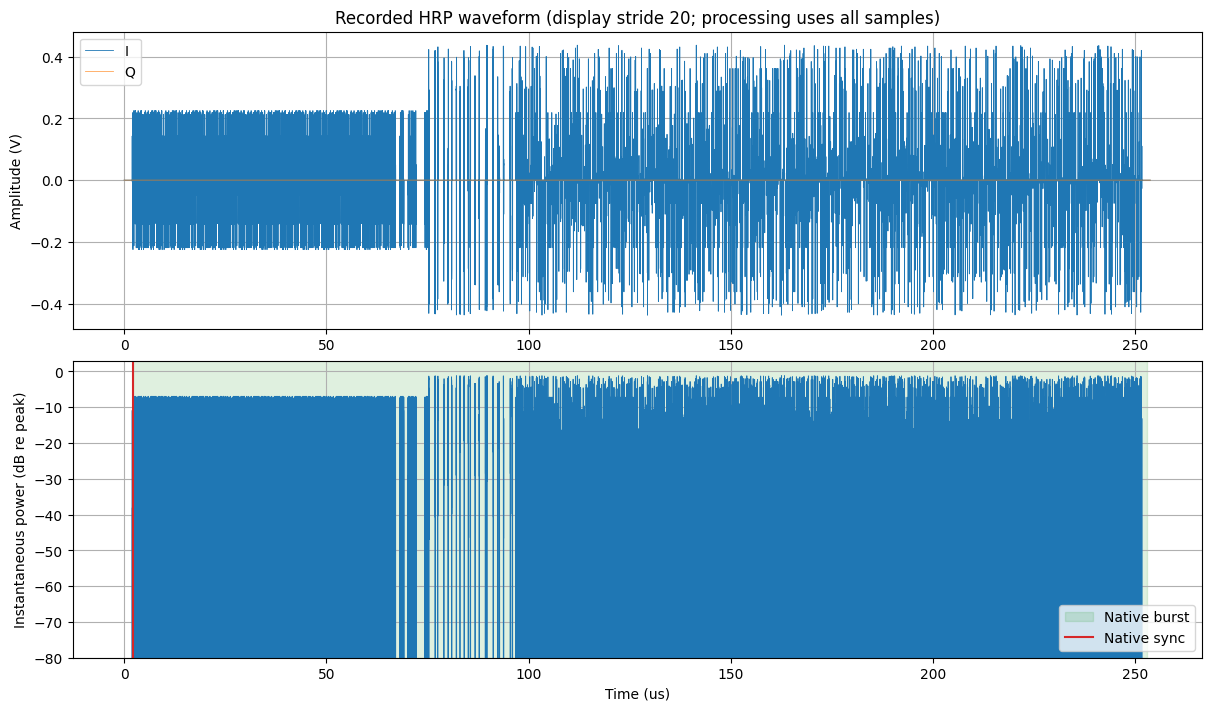

Burst: samples [4156, 504878); duration 250.762 us


In [3]:
# 2. Inspect I/Q and power; overlay the native burst interval.
time_us = np.arange(iq.size) / fs * 1e6
power = np.abs(iq.astype(np.complex128)) ** 2
power_db = 10 * np.log10(np.maximum(power / power.max(), 1e-12))
burst_start = int(result.burstStart)
burst_end = min(iq.size, burst_start + int(result.burstLength))
sync_start = int(result.syncPositionSamples)
period = int(round(result.preambleSymbolPeriodSamples))
assert period > 0 and 0 <= sync_start < iq.size
stride = max(1, iq.size // 25000)
fig, axes = plt.subplots(2, 1, figsize=(12, 7), constrained_layout=True)
axes[0].plot(time_us[::stride], iq.real[::stride], label="I", linewidth=0.6)
axes[0].plot(time_us[::stride], iq.imag[::stride], label="Q", linewidth=0.6, alpha=0.7)
axes[0].set(ylabel="Amplitude (V)", title=f"Recorded HRP waveform (display stride {stride}; processing uses all samples)")
axes[0].legend()
axes[1].plot(time_us[::stride], power_db[::stride], linewidth=0.6)
axes[1].axvspan(burst_start / fs * 1e6, burst_end / fs * 1e6,
                color="tab:green", alpha=0.15, label="Native burst")
axes[1].axvline(sync_start / fs * 1e6, color="tab:red", label="Native sync")
axes[1].set(xlabel="Time (us)", ylabel="Instantaneous power (dB re peak)", ylim=(-80, 3))
axes[1].legend()
plt.show()
print(f"Burst: samples [{burst_start}, {burst_end}); duration {(burst_end - burst_start) / fs * 1e6:.3f} us")

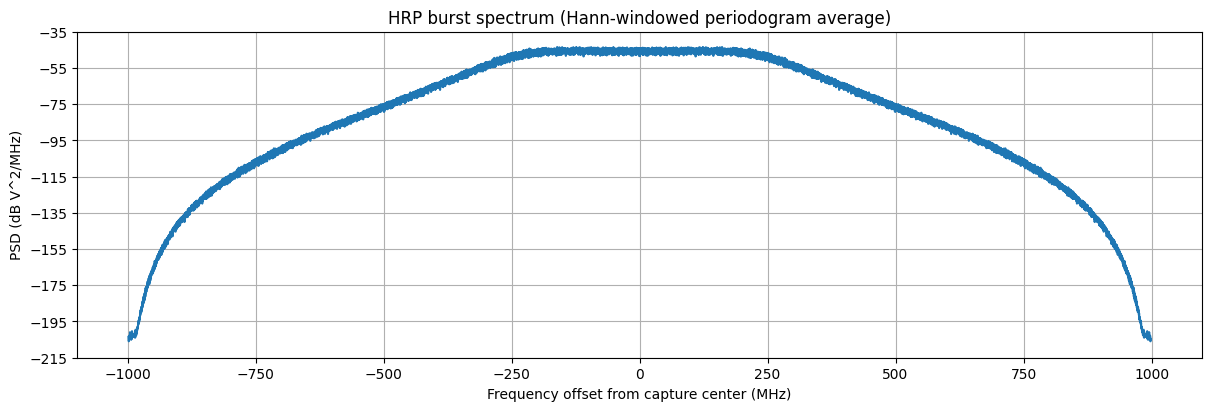

In [4]:
# 3. Estimate the two-sided complex-baseband power spectral density.
fig, axis = plt.subplots(figsize=(12, 4), constrained_layout=True)
axis.psd(iq[burst_start:burst_end], NFFT=8192, Fs=fs / 1e6,
         sides="twosided", scale_by_freq=True)
axis.set(title="HRP burst spectrum (Hann-windowed periodogram average)",
         xlabel="Frequency offset from capture center (MHz)", ylabel="PSD (dB V^2/MHz)")
plt.show()

C:\Users\Peng.Zhou\AppData\Local\Temp\ipykernel_17164\214851309.py:32: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  fig.colorbar(image, ax=axes[1], label="Amplitude (V)")


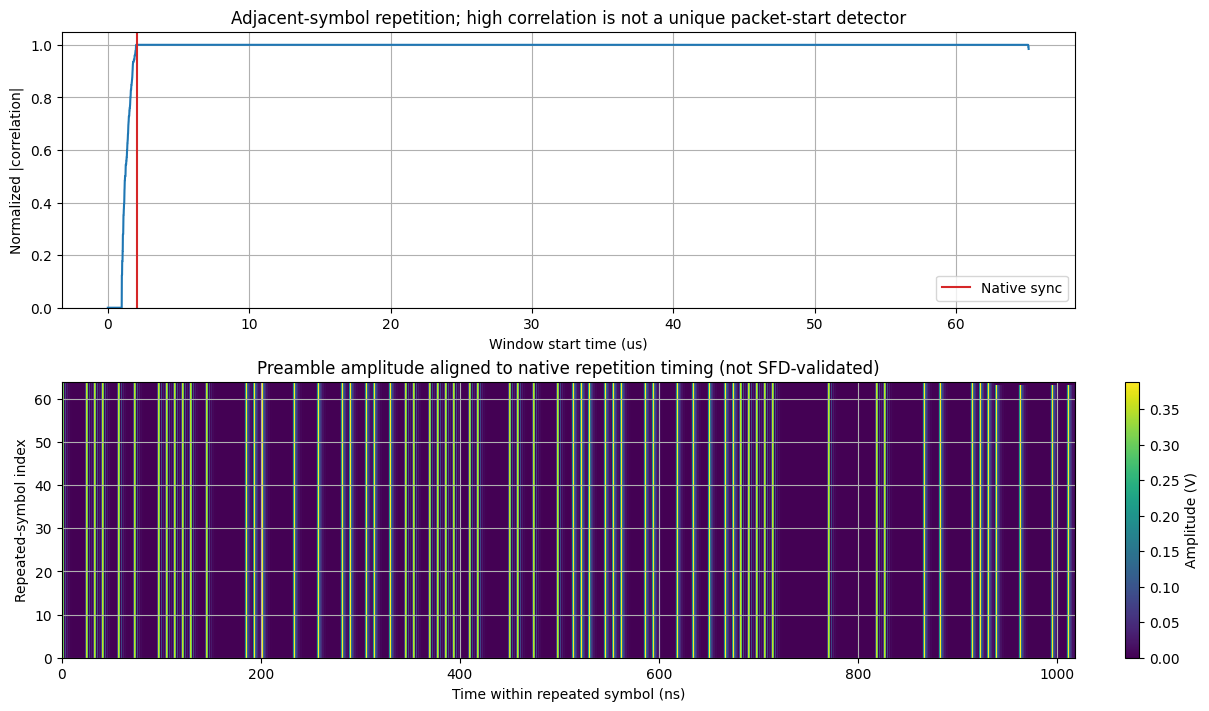

Native period: 2032 samples = 1017.628 ns
Native sync rho: 0.990390; independent repetition maximum: 1.000000


In [5]:
# 4. Measure normalized repetition correlation between adjacent preamble symbols.
# This is a notebook diagnostic, not an internal native-core trace.
window_count = min(64 * period, iq.size - 2 * period)
assert window_count > 0
first = iq[:window_count + period].astype(np.complex128)
second = iq[period:window_count + 2 * period].astype(np.complex128)

def moving_sum(values, length):
    cumulative = np.concatenate(([0], np.cumsum(values)))
    return cumulative[length:] - cumulative[:-length]

cross = moving_sum(np.conj(first) * second, period)
energy_first = moving_sum(np.abs(first) ** 2, period).real
energy_second = moving_sum(np.abs(second) ** 2, period).real
denominator = np.sqrt(np.maximum(energy_first, 0) * np.maximum(energy_second, 0))
rho = np.divide(np.abs(cross), denominator, out=np.zeros_like(denominator),
                where=denominator > np.max(denominator) * 1e-8)
rho = np.clip(rho, 0, 1)
fig, axes = plt.subplots(2, 1, figsize=(12, 7), constrained_layout=True)
axes[0].plot(np.arange(rho.size) / fs * 1e6, rho)
axes[0].axvline(sync_start / fs * 1e6, color="tab:red", label="Native sync")
axes[0].set(xlabel="Window start time (us)", ylabel="Normalized |correlation|", ylim=(0, 1.05),
            title="Adjacent-symbol repetition; high correlation is not a unique packet-start detector")
axes[0].legend()
preamble_count = min(config.syncLength, (iq.size - sync_start) // period)
assert preamble_count >= 2
preamble = iq[sync_start:sync_start + preamble_count * period].reshape(preamble_count, period)
image = axes[1].imshow(np.abs(preamble), aspect="auto", origin="lower", interpolation="nearest",
                        extent=(0, period / fs * 1e9, 0, preamble_count), cmap="viridis")
axes[1].set(xlabel="Time within repeated symbol (ns)", ylabel="Repeated-symbol index",
            title="Preamble amplitude aligned to native repetition timing (not SFD-validated)")
fig.colorbar(image, ax=axes[1], label="Amplitude (V)")
plt.show()
assert np.isfinite(rho).all()
print(f"Native period: {period} samples = {period / fs * 1e9:.3f} ns")
print(f"Native sync rho: {result.syncRho:.6f}; independent repetition maximum: {rho.max():.6f}")

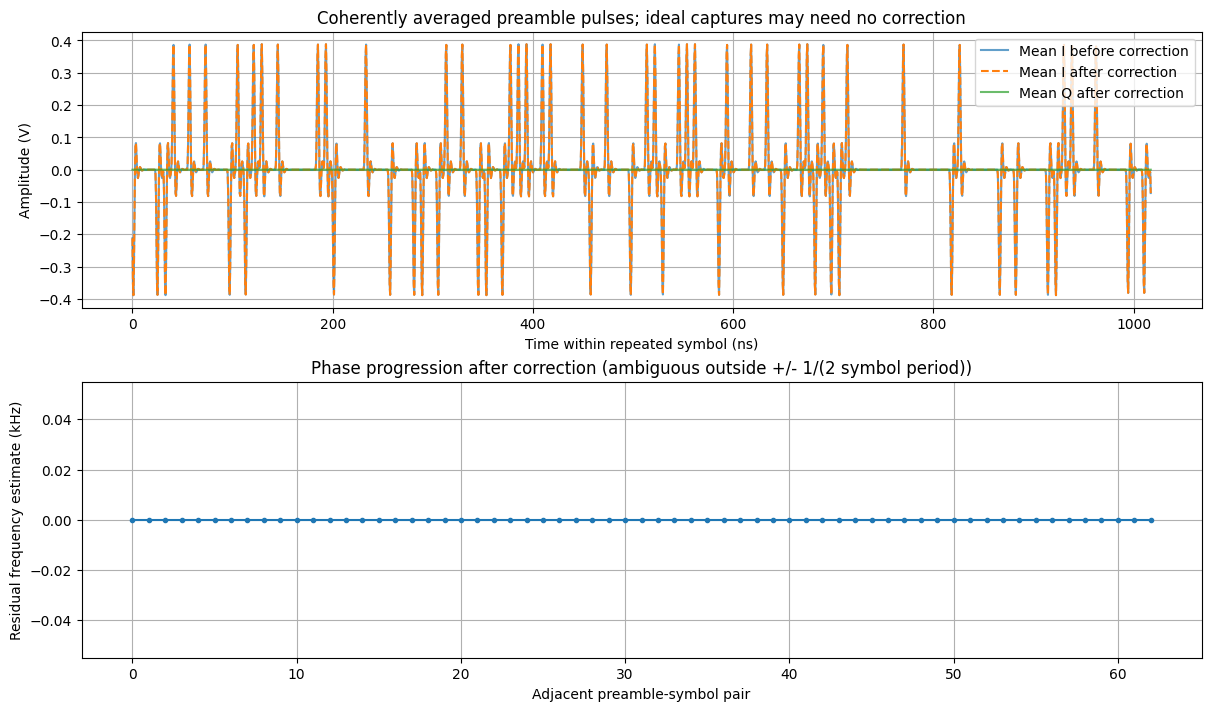

Applied native frequency correction: -0.000 Hz
Median repetition-based residual: 0.000 Hz

Receiver summary
Burst detected: True; preamble synchronized: True
Sync sample: 4156; sync metric: 0.990390
Payload decoding, CRC, and EVM: NOT AVAILABLE in the native HRP API
Generator reference only: PSDU length 127 bytes


In [6]:
# 5. Correct the native frequency estimate and coherently average preamble pulses.
frequency_error_hz = float(result.frequencyErrorHz)
corrected = iq * np.exp(-2j * np.pi * frequency_error_hz * np.arange(iq.size) / fs)
aligned = corrected[sync_start:sync_start + preamble_count * period].reshape(preamble_count, period)
average_before = preamble.mean(axis=0)
average_after = aligned.mean(axis=0)
phase_step = np.angle(np.sum(np.conj(aligned[:-1]) * aligned[1:], axis=1))
residual_hz = phase_step * fs / (2 * np.pi * period)
fig, axes = plt.subplots(2, 1, figsize=(12, 7), constrained_layout=True)
within_ns = np.arange(period) / fs * 1e9
axes[0].plot(within_ns, average_before.real, label="Mean I before correction", alpha=0.7)
axes[0].plot(within_ns, average_after.real, "--", label="Mean I after correction")
axes[0].plot(within_ns, average_after.imag, label="Mean Q after correction", alpha=0.7)
axes[0].set(xlabel="Time within repeated symbol (ns)", ylabel="Amplitude (V)",
            title="Coherently averaged preamble pulses; ideal captures may need no correction")
axes[0].legend()
axes[1].plot(np.arange(residual_hz.size), residual_hz / 1e3, marker=".")
axes[1].set(xlabel="Adjacent preamble-symbol pair", ylabel="Residual frequency estimate (kHz)",
            title="Phase progression after correction (ambiguous outside +/- 1/(2 symbol period))")
plt.show()
assert np.isfinite(corrected).all() and np.isfinite(residual_hz).all()
print(f"Applied native frequency correction: {frequency_error_hz:.3f} Hz")
print(f"Median repetition-based residual: {np.median(residual_hz):.3f} Hz")

# 6. Report only receiver results actually available from this core.
print("\nReceiver summary")
print(f"Burst detected: {result.burstFound}; preamble synchronized: {result.syncFound}")
print(f"Sync sample: {sync_start}; sync metric: {result.syncRho:.6f}")
print("Payload decoding, CRC, and EVM: NOT AVAILABLE in the native HRP API")
print(f"Generator reference only: PSDU length {settings['PSDULength']} bytes")